边界元法BEM参考解

=== 多核满血版纯 BEM 求解二维弹性受压方板 ===
E = 1.0e+06 Pa, nu = 0.3, 网格数 N = 800
正在编译并多核组装矩阵...
H, G 矩阵组装完成，耗时: 1.668 s
线性方程组求逆完成，耗时: 0.049 s 
正在多核全速计算域内物理场 (含4倍有限差分)...
全域位移与偏导数提取完成，耗时: 1.939 s 


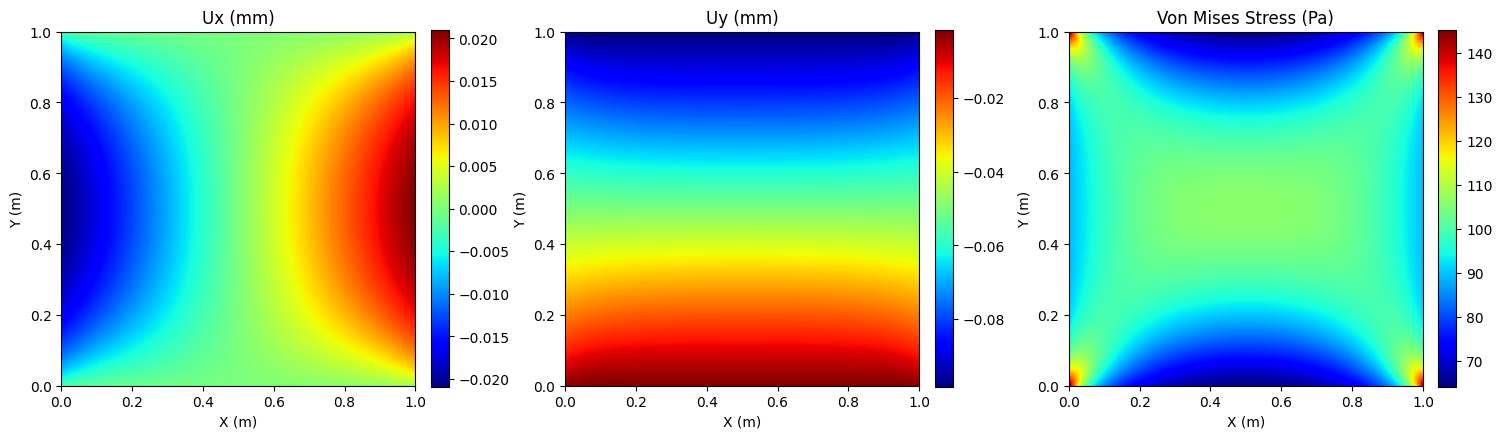

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
import time

# ==========================================
# 1. 物理参数与网格参数
# ==========================================
L = 1.0              # 正方形边长 (m)
E = 1.0e6            # 杨氏模量 (Pa)
nu = 0.3             # 泊松比
disp_top = -1e-4     # 顶边法向位移 (m)

nu_eff = nu 
G_shear = E / (2.0 * (1.0 + nu))

n_per_side = 200      # 每边单元数 (总数 N = 800)
N = n_per_side * 4

print(f"=== 多核满血版纯 BEM 求解二维弹性受压方板 ===")
print(f"E = {E:.1e} Pa, nu = {nu}, 网格数 N = {N}")

# ==========================================
# 2. 生成常数边界单元网格
# ==========================================
nodes = np.zeros((N, 2))
normals = np.zeros((N, 2))
lengths = np.zeros(N)
edge_ids = np.zeros(N, dtype=int)

dl = L / n_per_side
coords = np.linspace(dl/2, L - dl/2, n_per_side)

idx = 0
for x in coords:
    nodes[idx] = [x, 0]; normals[idx] = [0, -1]; lengths[idx] = dl; edge_ids[idx] = 0; idx += 1
for y in coords:
    nodes[idx] = [L, y]; normals[idx] = [1, 0]; lengths[idx] = dl; edge_ids[idx] = 1; idx += 1
for x in coords[::-1]:
    nodes[idx] = [x, L]; normals[idx] = [0, 1]; lengths[idx] = dl; edge_ids[idx] = 2; idx += 1
for y in coords[::-1]:
    nodes[idx] = [0, y]; normals[idx] = [-1, 0]; lengths[idx] = dl; edge_ids[idx] = 3; idx += 1

# 常数提前计算好，以标量形式传入 Numba，加速极速
C1 = 1.0 / (8.0 * np.pi * G_shear * (1.0 - nu_eff))
C2 = 3.0 - 4.0 * nu_eff
C3 = -1.0 / (4.0 * np.pi * (1.0 - nu_eff))
C4 = 1.0 - 2.0 * nu_eff
gauss_xi, gauss_w = np.polynomial.legendre.leggauss(4)

# ==========================================
# 3. Numba 并行内核：组装 H 和 G 矩阵
# ==========================================
@njit(parallel=True)
def assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4):
    N = nodes.shape[0]
    H = np.zeros((2*N, 2*N))
    G = np.zeros((2*N, 2*N))
    n_gauss = len(gauss_xi)
    
    # prange 开启多线程并行，所有 CPU 核心将被瞬间拉满！
    for i in prange(N):
        x_source = nodes[i]
        for j in range(N):
            L_j = lengths[j]
            nx = normals[j, 0]; ny = normals[j, 1]
            tx = -ny; ty = nx
            
            r0 = 2*i; r1 = 2*i+1
            c0 = 2*j; c1 = 2*j+1
            
            if i == j:
                H[r0, c0] = 0.5; H[r0, c1] = 0.0
                H[r1, c0] = 0.0; H[r1, c1] = 0.5
                
                g00 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)) + 1.0)
                g11 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)))
                
                # 手工展开矩阵旋转相乘，避开 python 对象的创建开销
                G[r0, c0] = tx * (g00 * tx) + nx * (g11 * nx)
                G[r0, c1] = tx * (g00 * ty) + nx * (g11 * ny)
                G[r1, c0] = ty * (g00 * tx) + ny * (g11 * nx)
                G[r1, c1] = ty * (g00 * ty) + ny * (g11 * ny)
            else:
                y_center = nodes[j]
                H00 = 0.0; H01 = 0.0; H10 = 0.0; H11 = 0.0
                G00 = 0.0; G01 = 0.0; G10 = 0.0; G11 = 0.0
                
                for g in range(n_gauss):
                    y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                    y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                    
                    rx = y_gpx - x_source[0]
                    ry = y_gpy - x_source[1]
                    r = np.sqrt(rx*rx + ry*ry)
                    
                    rdx = rx / r; rdy = ry / r
                    dr_dn = rdx * nx + rdy * ny
                    log_1_r = np.log(1.0 / r)
                    
                    hw = 0.5 * L_j * gauss_w[g]
                    
                    # 彻底标量化展开 U_star 和 T_star，剔除一切 numpy 数组创建
                    G00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                    G01 += C1 * (rdx*rdy) * hw
                    G10 += C1 * (rdx*rdy) * hw
                    G11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                    
                    H00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                    H01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                    H10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                    H11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                    
                H[r0, c0] = H00; H[r0, c1] = H01
                H[r1, c0] = H10; H[r1, c1] = H11
                G[r0, c0] = G00; G[r0, c1] = G01
                G[r1, c0] = G10; G[r1, c1] = G11
                
    return H, G

t0 = time.time()
print("正在编译并多核组装矩阵...")
H, G = assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4)
print(f"H, G 矩阵组装完成，耗时: {time.time()-t0:.3f} s")

# ==========================================
# 4. 施加边界条件与线性求解 (保持不变)
# ==========================================
A = np.zeros((2*N, 2*N))
B = np.zeros(2*N)
u_known = np.zeros(2*N, dtype=bool); u_val = np.zeros(2*N)
t_known = np.zeros(2*N, dtype=bool); t_val = np.zeros(2*N)

for i in range(N):
    eid = edge_ids[i]
    dof_x, dof_y = 2*i, 2*i+1
    
    if eid == 0:   
        u_known[dof_x] = True; u_val[dof_x] = 0.0
        u_known[dof_y] = True; u_val[dof_y] = 0.0
    elif eid == 2: 
        # 注意这里已经修复为了 u_x = 0 (不滑移摩擦边界)
        u_known[dof_x] = True; u_val[dof_x] = 0.0
        u_known[dof_y] = True; u_val[dof_y] = disp_top
    else:          
        t_known[dof_x] = True; t_val[dof_x] = 0.0
        t_known[dof_y] = True; t_val[dof_y] = 0.0

for k in range(2*N):
    if u_known[k]:
        A[:, k] = -G[:, k]
        B -= H[:, k] * u_val[k]
    else:
        A[:, k] = H[:, k]
        B += G[:, k] * t_val[k]

t1 = time.time()
X = np.linalg.solve(A, B)
print(f"线性方程组求逆完成，耗时: {time.time()-t1:.3f} s ")

u_bnd = np.zeros(2*N)
t_bnd = np.zeros(2*N)
for k in range(2*N):
    if u_known[k]:
        u_bnd[k] = u_val[k]; t_bnd[k] = X[k]
    else:
        u_bnd[k] = X[k]; t_bnd[k] = t_val[k]

# ==========================================
# 5. Numba 并行内核：极速计算内部场
# ==========================================
@njit(parallel=True)
def calc_internal_u_numba(pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd):
    N_pts = pts.shape[0]
    N = nodes.shape[0]
    n_gauss = len(gauss_xi)
    u_out = np.zeros((N_pts, 2))
    
    for q in prange(N_pts):
        xi_x = pts[q, 0]; xi_y = pts[q, 1]
        u_x = 0.0; u_y = 0.0
        
        for j in range(N):
            y_center = nodes[j]
            L_j = lengths[j]
            nx = normals[j, 0]; ny = normals[j, 1]
            tx = -ny; ty = nx
            
            U00 = 0.0; U01 = 0.0; U10 = 0.0; U11 = 0.0
            T00 = 0.0; T01 = 0.0; T10 = 0.0; T11 = 0.0
            
            for g in range(n_gauss):
                y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                
                rx = y_gpx - xi_x; ry = y_gpy - xi_y
                r = np.sqrt(rx*rx + ry*ry)
                rdx = rx / r; rdy = ry / r
                dr_dn = rdx * nx + rdy * ny
                log_1_r = np.log(1.0 / r)
                hw = 0.5 * L_j * gauss_w[g]
                
                U00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                U01 += C1 * (rdx*rdy) * hw
                U10 += C1 * (rdx*rdy) * hw
                U11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                
                T00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                T01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                T10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                T11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                
            uj_x = u_bnd[2*j]; uj_y = u_bnd[2*j+1]
            tj_x = t_bnd[2*j]; tj_y = t_bnd[2*j+1]
            
            u_x += (U00*tj_x + U01*tj_y) - (T00*uj_x + T01*uj_y)
            u_y += (U10*tj_x + U11*tj_y) - (T10*uj_x + T11*uj_y)
            
        u_out[q, 0] = u_x
        u_out[q, 1] = u_y
        
    return u_out

print("正在多核全速计算域内物理场 (含4倍有限差分)...")
grid_size = 200
coords_1d = np.linspace(0.02, 0.98, grid_size)
XX, YY = np.meshgrid(coords_1d, coords_1d)
internal_pts = np.c_[XX.ravel(), YY.ravel()]

t2 = time.time()
u_int = calc_internal_u_numba(internal_pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

eps_delta = 1e-4
u_px = calc_internal_u_numba(internal_pts + np.array([eps_delta, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_mx = calc_internal_u_numba(internal_pts - np.array([eps_delta, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_py = calc_internal_u_numba(internal_pts + np.array([0.0, eps_delta]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_my = calc_internal_u_numba(internal_pts - np.array([0.0, eps_delta]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

du_dx = (u_px - u_mx) / (2*eps_delta)
du_dy = (u_py - u_my) / (2*eps_delta)
print(f"全域位移与偏导数提取完成，耗时: {time.time()-t2:.3f} s ")

# 后处理应变与应力
eps_xx = du_dx[:, 0]
eps_yy = du_dy[:, 1]
eps_xy = 0.5 * (du_dx[:, 1] + du_dy[:, 0])

lam = E * nu / ((1 + nu) * (1 - 2 * nu))
mu_lame = E / (2 * (1 + nu))

sig_xx = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_xx
sig_yy = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_yy
sig_xy = 2 * mu_lame * eps_xy

# 【关键修正】：平面应变状态下，Z方向存在约束反力！
sig_zz = nu * (sig_xx + sig_yy)

# 使用完整的三维 Von Mises 公式
von_mises = np.sqrt(0.5 * ((sig_xx - sig_yy)**2 + 
                           (sig_yy - sig_zz)**2 + 
                           (sig_zz - sig_xx)**2) + 
                    3 * sig_xy**2)

# ==========================================
# 6. 绘图与出图
# ==========================================
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(18, 5))

extent = [0, L, 0, L]

# 使用 GridSpec 控制颜色条和子图对齐
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.3)

# Ux
ax0 = fig.add_subplot(gs[0, 0])
im0 = ax0.imshow(u_int[:,0].reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent,
                 cmap='jet', aspect='equal')
ax0.set_xlabel('X (m)'); ax0.set_ylabel('Y (m)')
# 色条和子图等高
cbar0 = fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)
ax0.set_title('Ux (mm)')

# Uy
ax1 = fig.add_subplot(gs[0, 1])
im1 = ax1.imshow(u_int[:,1].reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent,
                 cmap='jet', aspect='equal')
ax1.set_xlabel('X (m)'); ax1.set_ylabel('Y (m)')
cbar1 = fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_title('Uy (mm)')

# Von Mises
ax2 = fig.add_subplot(gs[0, 2])
im2 = ax2.imshow(von_mises.reshape(grid_size, grid_size), origin='lower', extent=extent,
                 cmap='jet', aspect='equal')
ax2.set_xlabel('X (m)'); ax2.set_ylabel('Y (m)')
cbar2 = fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
ax2.set_title('Von Mises Stress (Pa)')

plt.show()

# FSNet: Fundamental Solution Network

这个 notebook 是独立的 FSNet 脚本，不修改原来的 MFS.ipynb。

网络结构是单隐藏层形式：隐藏层固定为 KM 复势基本解核函数，输出层是可训练权重。也就是说，源点充当 kernel centers，网络训练的是基本解线性组合系数。

训练只使用边界条件：底边固定位移、顶边给定位移、左右边自由面力。

=== MFS 基本解法参数 ===
L = 1.0, E_real = 1.000e+06 Pa, nu = 0.3, disp_top_real = -1.000e-04 m
归一化: scale_u = 1.000e+04, disp_top* = -1.000e+00, E* = 1.0


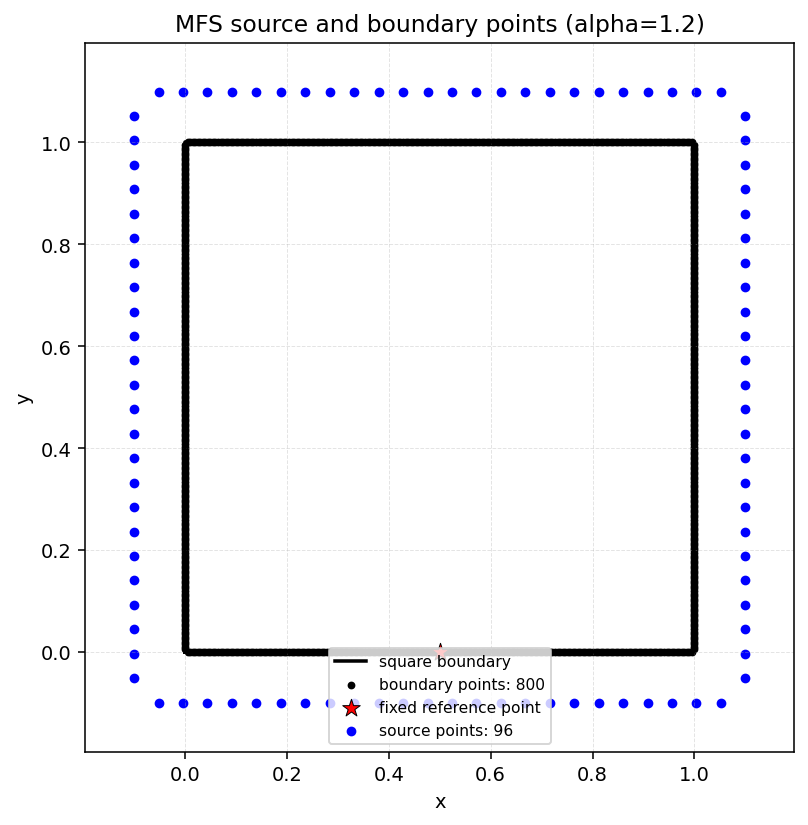

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time

try:
    import pandas as pd
except ImportError:
    pd = None

try:
    from IPython.display import display
except ImportError:
    display = print

# ==========================================
# 1. 参数与归一化
# ==========================================
# 若前一个 BEM 参考解单元已经运行，这里直接沿用 L、E、nu、disp_top。
L_MFS = float(globals().get("L", 1.0))
E_REAL_MFS = float(globals().get("E", 1.0e6))
NU_MFS = float(globals().get("nu", 0.3))
DISP_TOP_REAL_MFS = float(globals().get("disp_top", -1.0e-4))

# 与前面神经网络 notebook 保持一致：位移放大到顶部位移约为 -1。
SCALE_U_MFS = 1.0 / max(abs(DISP_TOP_REAL_MFS), 1e-15)
E_STAR_MFS = 1.0
DISP_TOP_MFS = DISP_TOP_REAL_MFS * SCALE_U_MFS
G_MFS = E_STAR_MFS / (2.0 * (1.0 + NU_MFS))
KAPPA_MFS = 3.0 - 4.0 * NU_MFS  # 平面应变
STRESS_TO_REAL_MFS = E_REAL_MFS / SCALE_U_MFS

# 默认计算组合
N_SOURCES_PER_SIDE = 24      # 外部源点正方形每条边源点数，不含角点
N_BND_PER_EDGE = 200         # 真实边界每条边配点数，不含角点
SOURCE_SCALE = 1.2           # 外部源点正方形边长比例 alpha

print("=== MFS 基本解法参数 ===")
print(f"L = {L_MFS}, E_real = {E_REAL_MFS:.3e} Pa, nu = {NU_MFS}, disp_top_real = {DISP_TOP_REAL_MFS:.3e} m")
print(f"归一化: scale_u = {SCALE_U_MFS:.3e}, disp_top* = {DISP_TOP_MFS:.3e}, E* = {E_STAR_MFS}")

# ==========================================
# 2. 源点、边界配点生成与可视化
# ==========================================
def build_boundary_points(n_bnd_per_edge=N_BND_PER_EDGE):
    """真实正方形边界配点，不取角点。"""
    t = np.linspace(0.0, L_MFS, int(n_bnd_per_edge) + 2, dtype=float)[1:-1]
    z = np.zeros_like(t)
    o = np.full_like(t, L_MFS)
    return {
        "bottom": np.column_stack([t, z]),
        "right": np.column_stack([o, t]),
        "top": np.column_stack([t[::-1], o]),
        "left": np.column_stack([z, t[::-1]]),
    }

def boundary_points_as_array(boundary_points):
    return np.vstack([boundary_points["bottom"], boundary_points["right"],
                      boundary_points["top"], boundary_points["left"]])

def build_source_points(n_sources_per_side=N_SOURCES_PER_SIDE, source_scale=SOURCE_SCALE):
    """按外部相似正方形布置源点，每条外部边向外平移相同距离，不包含角点。"""
    n = int(n_sources_per_side)
    alpha = float(source_scale)
    if n <= 0:
        raise ValueError("n_sources_per_side 必须为正整数")
    if alpha <= 1.0:
        raise ValueError("source_scale 必须大于 1，源点必须位于真实区域外部")

    center = 0.5 * L_MFS
    half_outer = 0.5 * alpha * L_MFS
    lo = center - half_outer
    hi = center + half_outer

    # 不取角点。alpha=3 且 L=1 时，外部源点正方形为 [-1, 2] x [-1, 2]。
    t = np.linspace(lo, hi, n + 2, dtype=float)[1:-1]
    bottom = np.column_stack([t, np.full_like(t, lo)])
    right = np.column_stack([np.full_like(t, hi), t])
    top = np.column_stack([t[::-1], np.full_like(t, hi)])
    left = np.column_stack([np.full_like(t, lo), t[::-1]])
    return np.vstack([bottom, right, top, left])

def plot_source_boundary_points(n_sources_per_side=N_SOURCES_PER_SIDE,
                                n_bnd_per_edge=N_BND_PER_EDGE,
                                source_scale=SOURCE_SCALE,
                                ax=None):
    src = build_source_points(n_sources_per_side, source_scale)
    bnd = build_boundary_points(n_bnd_per_edge)
    bnd_all = boundary_points_as_array(bnd)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6.2, 6.0), dpi=140)
    else:
        fig = ax.figure

    square = np.array([[0, 0], [L_MFS, 0], [L_MFS, L_MFS], [0, L_MFS], [0, 0]], dtype=float)
    ax.plot(square[:, 0], square[:, 1], color="black", lw=1.8, label="square boundary")
    ax.scatter(bnd_all[:, 0], bnd_all[:, 1], s=9, c="black", label=f"boundary points: {len(bnd_all)}")
    ax.scatter([0.5 * L_MFS], [0.0], marker="*", s=90, c="red", edgecolors="black",
               linewidths=0.5, label="fixed reference point", zorder=4)
    ax.scatter(src[:, 0], src[:, 1], s=16, c="blue", label=f"source points: {len(src)}")

    margin = 0.08 * max(L_MFS, np.ptp(src[:, 0]), np.ptp(src[:, 1]))
    ax.set_xlim(src[:, 0].min() - margin, src[:, 0].max() + margin)
    ax.set_ylim(src[:, 1].min() - margin, src[:, 1].max() + margin)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"MFS source and boundary points (alpha={source_scale:g})")
    ax.grid(True, ls="--", lw=0.5, alpha=0.35)
    ax.legend(loc="lower center", frameon=True, fontsize=8)
    plt.tight_layout()
    return fig, ax, src, bnd

# 先画默认源点/边界点分布，确认源点是外部相似正方形，不是圆角外扩。
plot_source_boundary_points();


当前使用设备: cuda
=== FSNet: KM fundamental-solution kernel + single hidden layer ===
FSNet closed-form LS assembly: rows=1600, unknowns=392
FSNet LS init | rank=390 | rms=2.2120e-04 | max=2.6873e-03 | cond~=1.4920e+16
FSNet Adam fine-tune from LS initialization: epochs=300, lr=5.00e-04
Adam     0/300 | loss=3.9143e-07
Adam    60/300 | loss=1.8798e-04
Adam   120/300 | loss=6.5233e-07
Adam   180/300 | loss=4.8527e-07
Adam   240/300 | loss=6.8951e-05
Adam   299/300 | loss=5.9083e-07
FSNet L-BFGS fine-tune from current network state: max_iter=300
L-BFGS    60 | loss=4.1530e-07
L-BFGS   120 | loss=4.0258e-07
L-BFGS   180 | loss=4.0074e-07
L-BFGS   240 | loss=4.0032e-07
L-BFGS   300 | loss=4.0003e-07
L-BFGS   360 | loss=3.9981e-07

=== FSNet 结果 ===


,source_per_side,source_total,boundary_per_edge,boundary_total,parameters,use_lstsq_init,adam_epochs,lbfgs_max_iter,final_boundary_loss,train_time_s,lstsq_rank,lstsq_boundary_rms,lstsq_boundary_max_abs,lstsq_condition_est,lstsq_solve_time_s,L2_ux,L2_uy,L2_mean,L2_max
0,24,96,200,800,392,True,300,300,3.997120e-07,17.73938,390,0.000221,0.002687,1.491966e+16,0.498405,0.001059,0.000111,0.000585,0.001059


FSNet 预测云图已保存: C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量预测云图\fsnet_prediction_clouds\fsnet_prediction_6_clouds.png
  C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量预测云图\fsnet_prediction_clouds\fsnet_prediction_ux.png
  C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量预测云图\fsnet_prediction_clouds\fsnet_prediction_uy.png
  C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量预测云图\fsnet_prediction_clouds\fsnet_prediction_sxx.png
  C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量预测云图\fsnet_prediction_clouds\fsnet_prediction_syy.png
  C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量预测云图\fsnet_prediction_clouds\fsnet_prediction_sxy.png
  C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量预测云图\fsnet_prediction_clouds\fsnet_prediction_von_mises.png


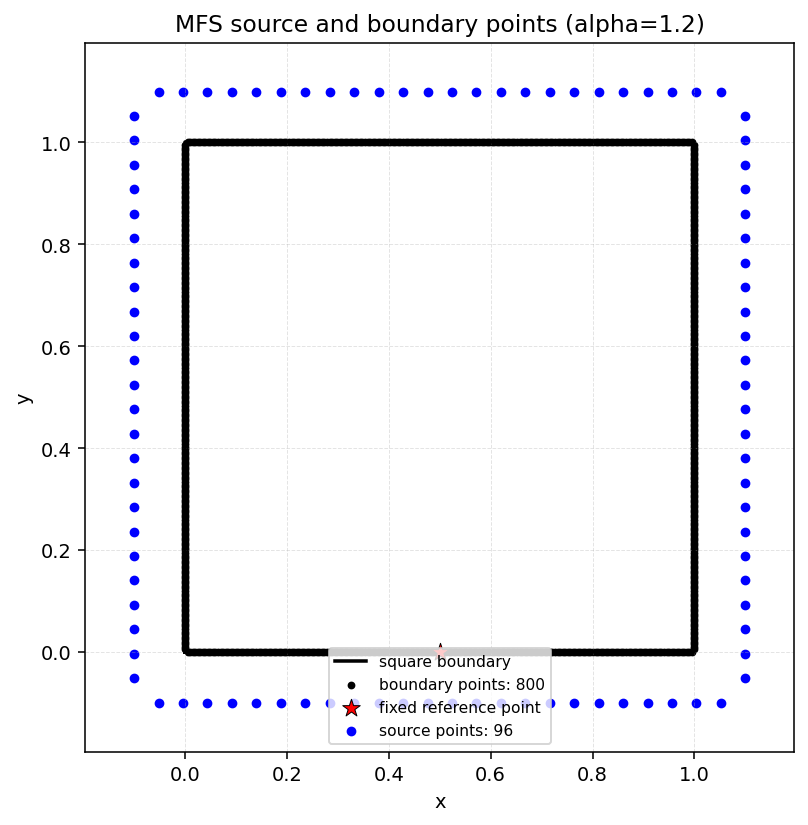

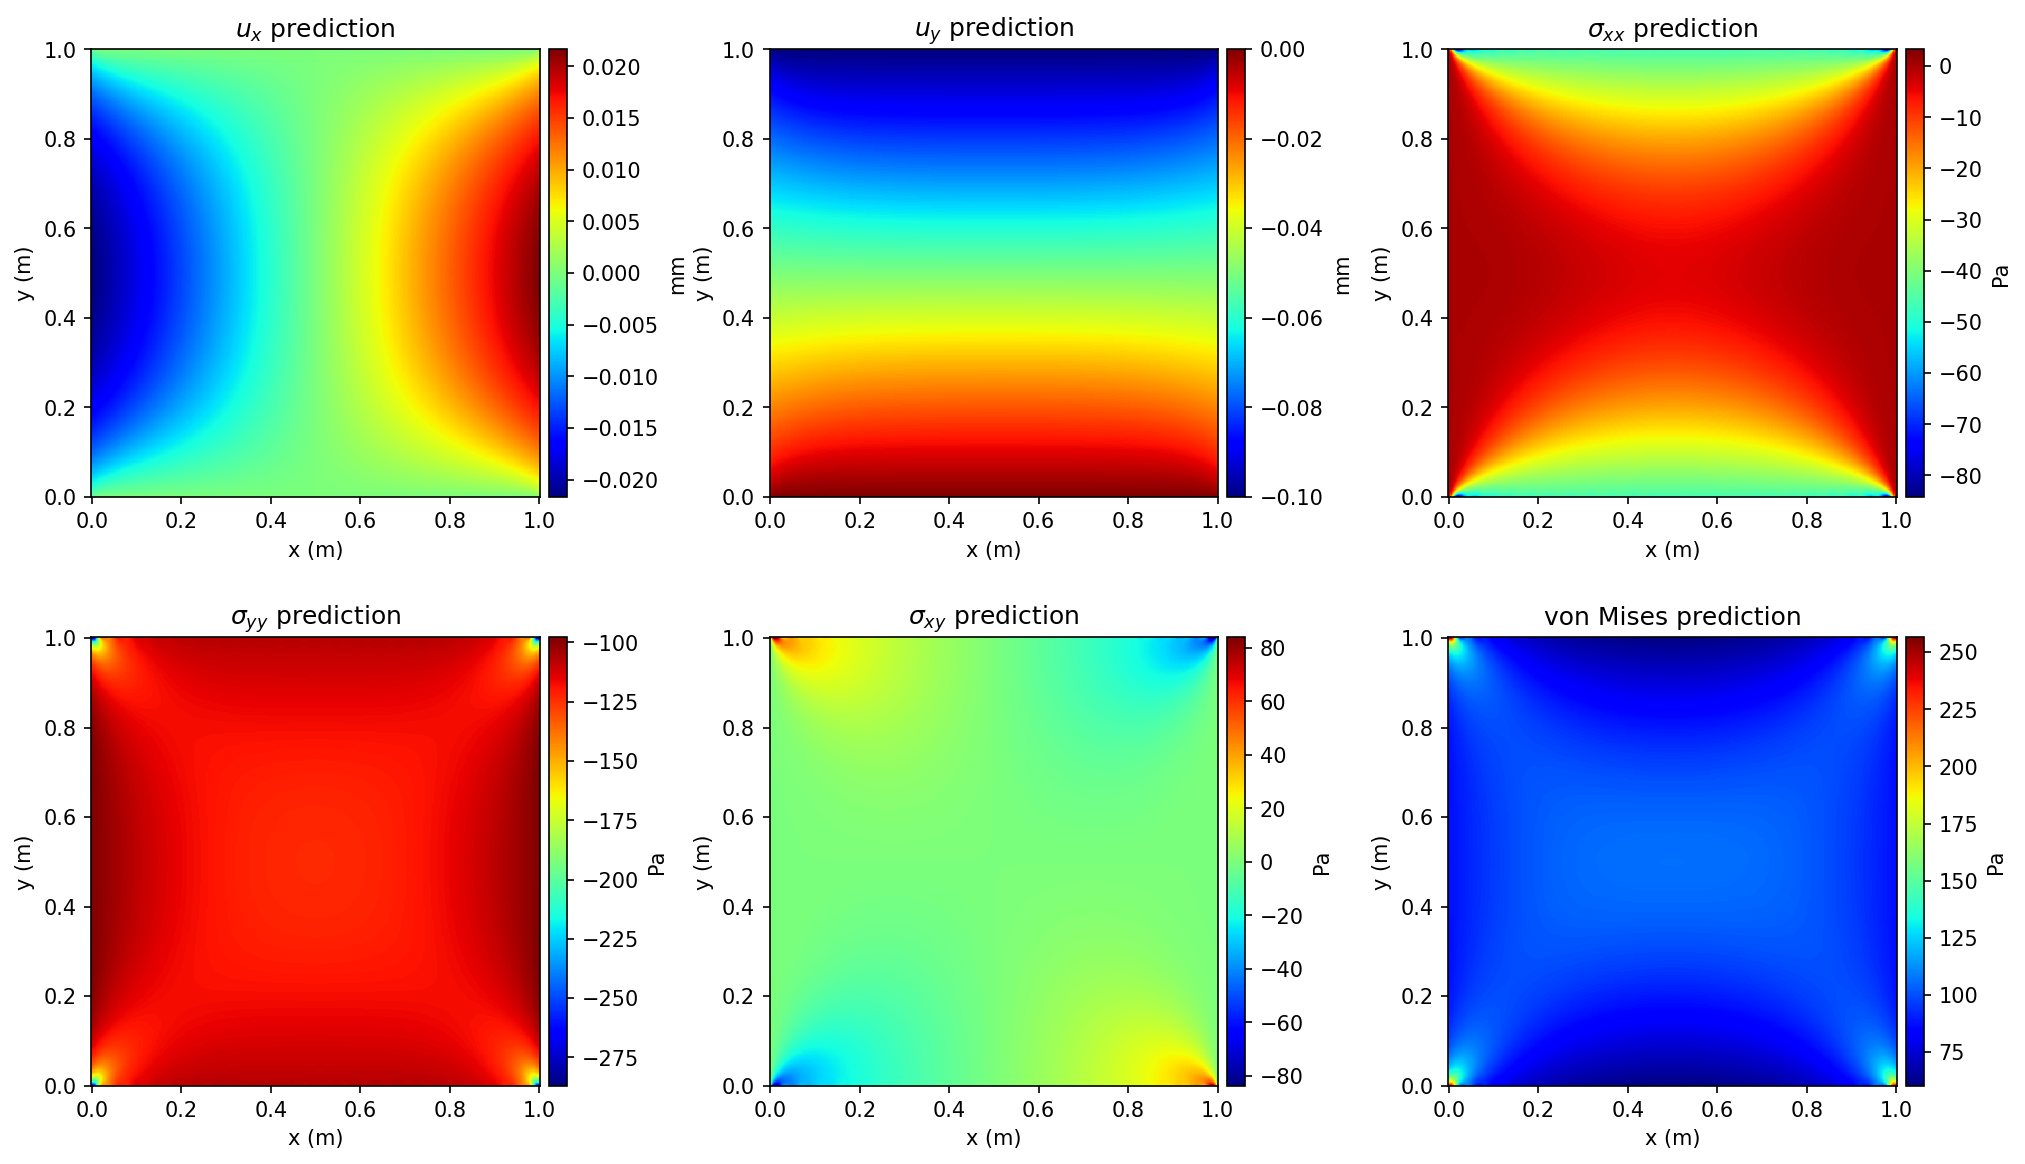

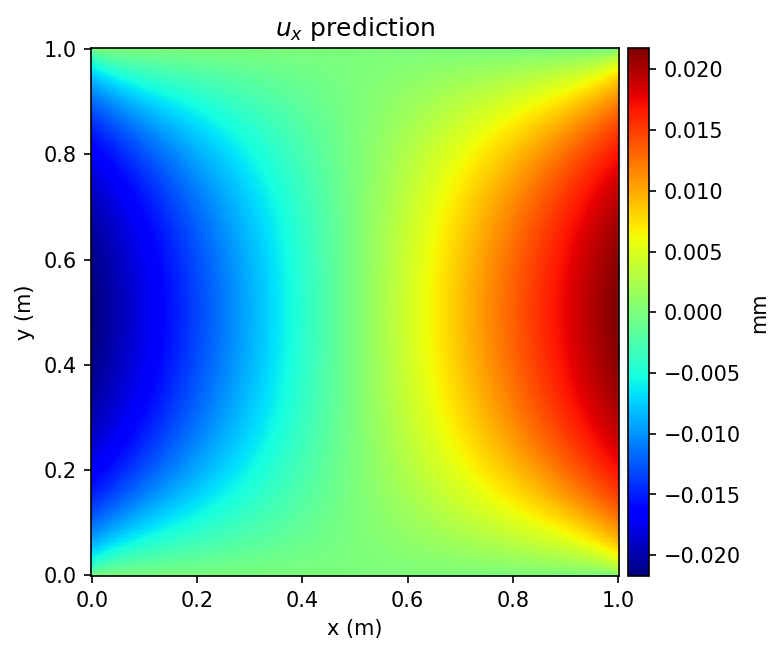

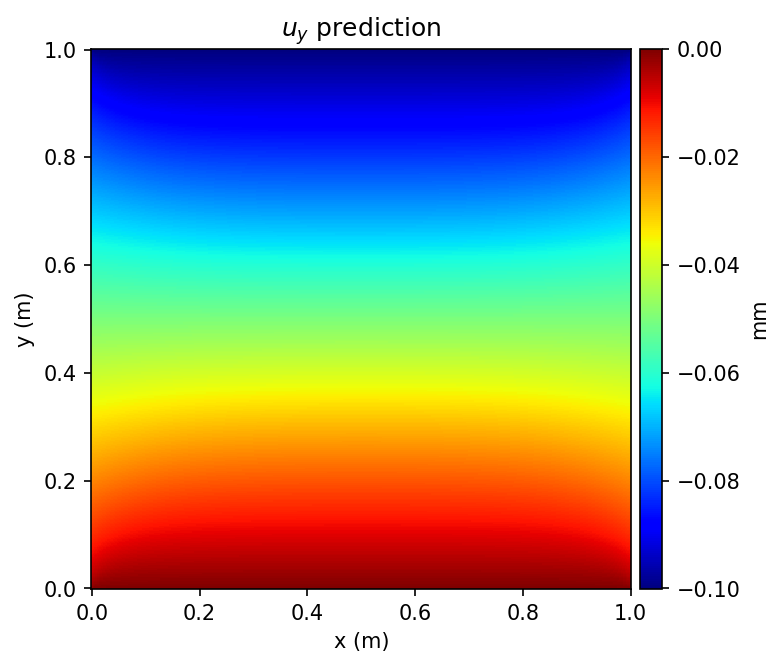

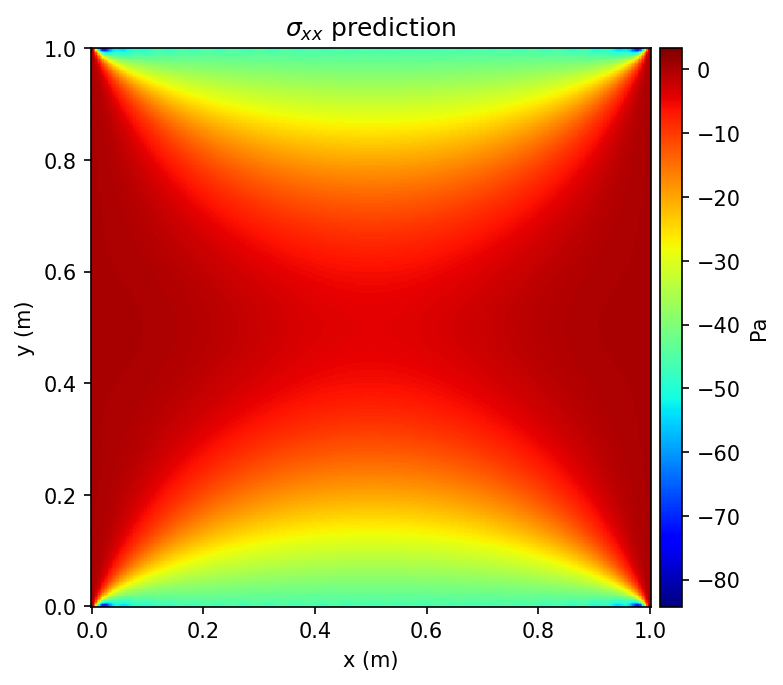

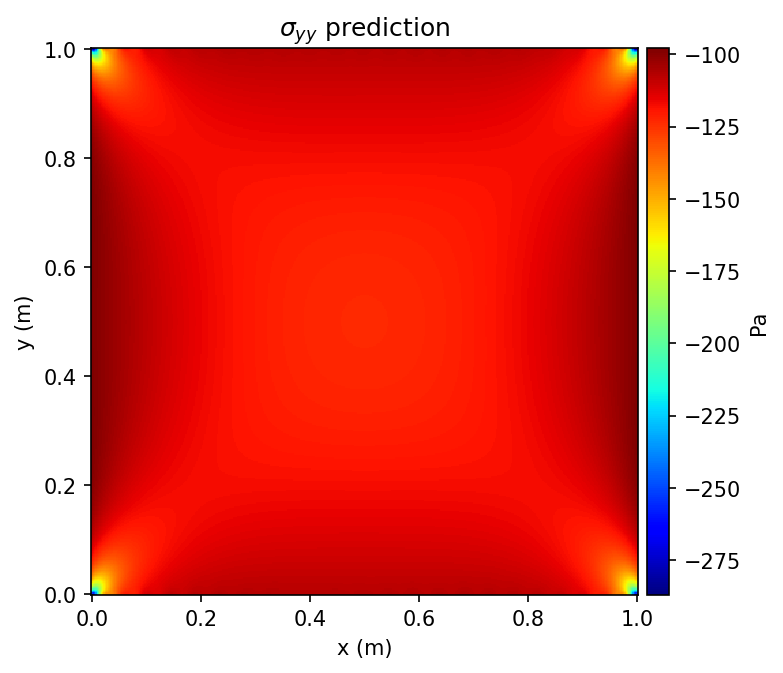

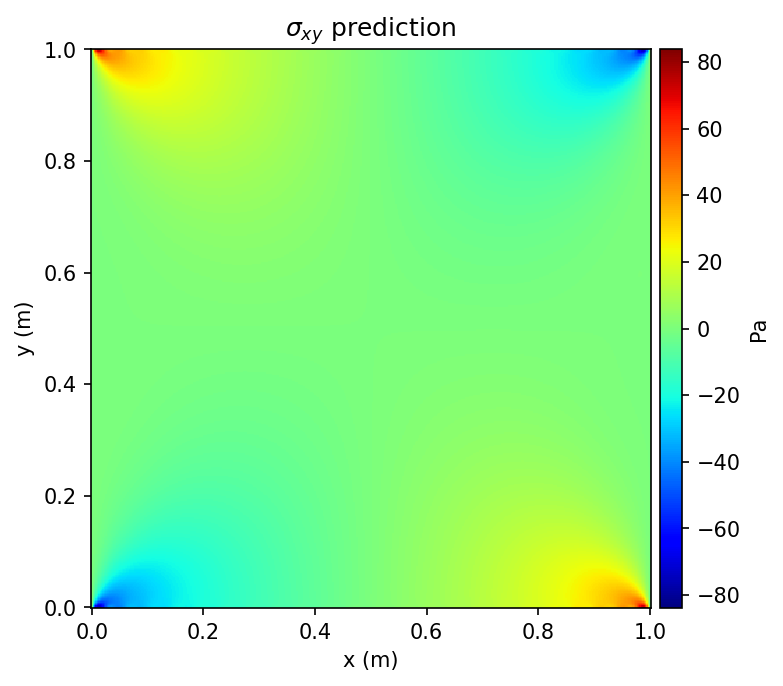

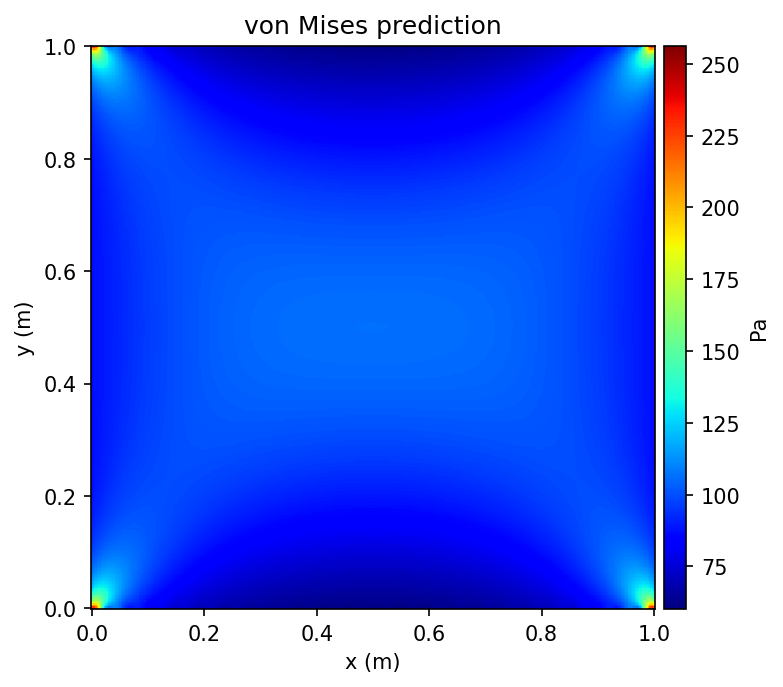

In [3]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time

try:
    import pandas as pd
except ImportError:
    pd = None

try:
    from IPython.display import display
except ImportError:
    display = print

# ==========================================
# 1. FSNet 设置
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch_dtype = torch.float64

print(f"当前使用设备: {device}")
print("=== FSNet: KM fundamental-solution kernel + single hidden layer ===")

def seed_everything(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

seed_everything(42)

# ==========================================
# 2. KM 基本解核函数与单隐藏层 FSNet
# ==========================================
class KMFundamentalKernel(nn.Module):
    """隐藏层：phi(||x-s_j||) = Log(z-zeta_j)，源点固定。"""
    def __init__(self, centers):
        super().__init__()
        centers = torch.as_tensor(centers, dtype=torch_dtype, device=device)
        self.register_buffer("centers", centers)

        center_z = torch.tensor([0.5 * L_MFS, 0.5 * L_MFS], dtype=torch_dtype, device=device)
        vec = center_z.view(1, 2) - centers
        branch_angle = torch.atan2(vec[:, 1], vec[:, 0])
        self.register_buffer("cos_theta", torch.cos(branch_angle))
        self.register_buffer("sin_theta", torch.sin(branch_angle))

    @property
    def n_centers(self):
        return int(self.centers.shape[0])

    def forward(self, x, y):
        dx = x - self.centers[:, 0].view(1, -1)
        dy = y - self.centers[:, 1].view(1, -1)
        r2 = torch.clamp(dx * dx + dy * dy, min=1e-30)

        # Log((z-zeta) exp(-i theta))，theta 只控制支路方向。
        rot_r = dx * self.cos_theta.view(1, -1) + dy * self.sin_theta.view(1, -1)
        rot_i = dy * self.cos_theta.view(1, -1) - dx * self.sin_theta.view(1, -1)

        basis_r = 0.5 * torch.log(r2)
        basis_i = torch.atan2(rot_i, rot_r)
        return basis_r, basis_i

class FSNet2D(nn.Module):
    """单隐藏层 FSNet：隐藏层是基本解核函数，输出层是可训练复权重。"""
    def __init__(self, centers, init_scale=1e-3):
        super().__init__()
        self.kernel = KMFundamentalKernel(centers)
        n = self.kernel.n_centers

        self.w_phi = nn.Parameter(torch.randn(n, 2, dtype=torch_dtype, device=device) * init_scale)
        self.w_psi = nn.Parameter(torch.randn(n, 2, dtype=torch_dtype, device=device) * init_scale)

        # 复仿射项：phi0 + phi1 z, psi0 + psi1 z。每行 [real, imag]。
        self.affine_phi = nn.Parameter(torch.zeros(2, 2, dtype=torch_dtype, device=device))
        self.affine_psi = nn.Parameter(torch.zeros(2, 2, dtype=torch_dtype, device=device))

    def _complex_linear(self, basis_r, basis_i, weights):
        wr = weights[:, 0]
        wi = weights[:, 1]
        out_r = basis_r @ wr - basis_i @ wi
        out_i = basis_r @ wi + basis_i @ wr
        return out_r.view(-1, 1), out_i.view(-1, 1)

    def _affine_z(self, x, y, coeffs):
        c0r, c0i = coeffs[0, 0], coeffs[0, 1]
        c1r, c1i = coeffs[1, 0], coeffs[1, 1]
        real = c0r + c1r * x - c1i * y
        imag = c0i + c1r * y + c1i * x
        return real, imag

    def forward(self, x, y):
        basis_r, basis_i = self.kernel(x, y)

        phi_r, phi_i = self._complex_linear(basis_r, basis_i, self.w_phi)
        psi_r, psi_i = self._complex_linear(basis_r, basis_i, self.w_psi)

        a_phi_r, a_phi_i = self._affine_z(x, y, self.affine_phi)
        a_psi_r, a_psi_i = self._affine_z(x, y, self.affine_psi)

        phi_r = phi_r + a_phi_r
        phi_i = phi_i + a_phi_i
        psi_r = psi_r + a_psi_r
        psi_i = psi_i + a_psi_i
        return phi_r, phi_i, psi_r, psi_i

def grad(outputs, inputs, create_graph=True):
    return torch.autograd.grad(
        outputs,
        inputs,
        grad_outputs=torch.ones_like(outputs),
        create_graph=create_graph,
        retain_graph=True,
    )[0]

def get_fsnet_phys_fields(model, x, y):
    phi_r, phi_i, psi_r, psi_i = model(x, y)

    dphi_r = grad(phi_r, x)
    dphi_i = grad(phi_i, x)
    dpsi_r = grad(psi_r, x)
    dpsi_i = grad(psi_i, x)

    d2phi_r = grad(dphi_r, x)
    d2phi_i = grad(dphi_i, x)

    kappa_f = float(KAPPA_MFS)
    G_f = float(G_MFS)

    # u = [kappa phi(z) - z * conj(phi'(z)) - conj(psi(z))] / (2G)
    z_conj_dphi_r = x * dphi_r + y * dphi_i
    z_conj_dphi_i = y * dphi_r - x * dphi_i
    ux = (kappa_f * phi_r - z_conj_dphi_r - psi_r) / (2.0 * G_f)
    uy = (kappa_f * phi_i - z_conj_dphi_i + psi_i) / (2.0 * G_f)

    # sigma_xx + sigma_yy = 4 Re(phi')
    # sigma_yy - sigma_xx + 2i sigma_xy = 2(conj(z) phi'' + psi')
    sum_sig = 4.0 * dphi_r
    diff_r = 2.0 * (x * d2phi_r + y * d2phi_i + dpsi_r)
    diff_i = 2.0 * (x * d2phi_i - y * d2phi_r + dpsi_i)

    sig_xx = 0.5 * (sum_sig - diff_r)
    sig_yy = 0.5 * (sum_sig + diff_r)
    sig_xy = 0.5 * diff_i
    return ux, uy, sig_xx, sig_yy, sig_xy

# ==========================================
# 3. 边界条件损失
# ==========================================
def _edge_tensors_fsnet(n_bnd):
    t = torch.linspace(0.0, L_MFS, int(n_bnd) + 2, device=device, dtype=torch_dtype)[1:-1].view(-1, 1)
    z = torch.zeros_like(t)
    o = torch.full_like(t, float(L_MFS))
    return {
        "bottom": (t.clone().requires_grad_(True), z.clone().requires_grad_(True)),
        "top": (t.clone().requires_grad_(True), o.clone().requires_grad_(True)),
        "left": (z.clone().requires_grad_(True), t.clone().requires_grad_(True)),
        "right": (o.clone().requires_grad_(True), t.clone().requires_grad_(True)),
    }

def get_fsnet_bnd_loss(model, n_bnd):
    edges = _edge_tensors_fsnet(n_bnd)

    x_bot, y_bot = edges["bottom"]
    ux_bot, uy_bot, _, _, _ = get_fsnet_phys_fields(model, x_bot, y_bot)
    loss_bot = torch.mean(ux_bot**2 + uy_bot**2)

    x_top, y_top = edges["top"]
    ux_top, uy_top, _, _, _ = get_fsnet_phys_fields(model, x_top, y_top)
    loss_top = torch.mean(ux_top**2 + (uy_top - DISP_TOP_MFS)**2)

    x_left, y_left = edges["left"]
    _, _, sig_xx_left, _, sig_xy_left = get_fsnet_phys_fields(model, x_left, y_left)
    loss_left = torch.mean(sig_xx_left**2 + sig_xy_left**2)

    x_right, y_right = edges["right"]
    _, _, sig_xx_right, _, sig_xy_right = get_fsnet_phys_fields(model, x_right, y_right)
    loss_right = torch.mean(sig_xx_right**2 + sig_xy_right**2)

    return loss_bot + loss_top + loss_left + loss_right

# --- Closed-form least-squares initialization for FSNet output layer ---
def _fsnet_as_complex(points):
    points = np.asarray(points, dtype=float)
    return points[:, 0] + 1j * points[:, 1]


def _fsnet_coefficient_count(n_basis):
    # phi source complex coeffs + psi source complex coeffs + complex constants/linear terms.
    return 4 * int(n_basis) + 8


def _fsnet_unpack_coeffs(coeffs, n_basis):
    coeffs = np.asarray(coeffs, dtype=float)
    n = int(n_basis)
    idx = 0
    w_phi = coeffs[idx:idx+n] + 1j * coeffs[idx+n:idx+2*n]
    idx += 2 * n
    w_psi = coeffs[idx:idx+n] + 1j * coeffs[idx+n:idx+2*n]
    idx += 2 * n
    phi0 = coeffs[idx] + 1j * coeffs[idx+1]
    idx += 2
    phi1 = coeffs[idx] + 1j * coeffs[idx+1]
    idx += 2
    psi0 = coeffs[idx] + 1j * coeffs[idx+1]
    idx += 2
    psi1 = coeffs[idx] + 1j * coeffs[idx+1]
    return w_phi, w_psi, phi0, phi1, psi0, psi1


def _fsnet_prepare_cache(points, source_points):
    z = _fsnet_as_complex(points)
    src_c = _fsnet_as_complex(source_points)
    dz = z[:, None] - src_c[None, :]

    center = 0.5 * L_MFS + 0.5j * L_MFS
    branch_angle = np.angle(center - src_c)
    rotated = dz * np.exp(-1j * branch_angle[None, :])

    basis = np.log(np.abs(rotated)) + 1j * np.angle(rotated)
    d1 = 1.0 / dz
    d2 = -1.0 / (dz * dz)
    return {
        "z": z,
        "basis": basis,
        "d1": d1,
        "d2": d2,
        "n_basis": len(src_c),
    }


def _fsnet_fields_from_coeffs(coeffs, cache):
    z = cache["z"]
    basis = cache["basis"]
    d1 = cache["d1"]
    d2 = cache["d2"]
    n_basis = cache["n_basis"]

    w_phi, w_psi, phi0, phi1, psi0, psi1 = _fsnet_unpack_coeffs(coeffs, n_basis)

    phi = basis @ w_phi + phi0 + phi1 * z
    psi = basis @ w_psi + psi0 + psi1 * z
    dphi = d1 @ w_phi + phi1
    d2phi = d2 @ w_phi
    dpsi = d1 @ w_psi + psi1

    disp_complex = (KAPPA_MFS * phi - z * np.conj(dphi) - np.conj(psi)) / (2.0 * G_MFS)
    ux = disp_complex.real
    uy = disp_complex.imag

    sum_sig = 4.0 * dphi.real
    diff = 2.0 * (np.conj(z) * d2phi + dpsi)
    sig_xx = 0.5 * (sum_sig - diff.real)
    sig_yy = 0.5 * (sum_sig + diff.real)
    sig_xy = 0.5 * diff.imag
    return ux, uy, sig_xx, sig_yy, sig_xy


def _fsnet_boundary_residual_numpy(coeffs, boundary_caches):
    ux_b, uy_b, _, _, _ = _fsnet_fields_from_coeffs(coeffs, boundary_caches["bottom"])
    ux_t, uy_t, _, _, _ = _fsnet_fields_from_coeffs(coeffs, boundary_caches["top"])
    _, _, sxx_l, _, sxy_l = _fsnet_fields_from_coeffs(coeffs, boundary_caches["left"])
    _, _, sxx_r, _, sxy_r = _fsnet_fields_from_coeffs(coeffs, boundary_caches["right"])

    return np.concatenate([
        ux_b,
        uy_b,
        ux_t,
        uy_t - DISP_TOP_MFS,
        sxx_l,
        sxy_l,
        sxx_r,
        sxy_r,
    ])


def solve_fsnet_output_layer_lstsq(source_points, n_bnd, rcond=None, progress=True):
    """Solve the fixed-kernel FSNet output layer by the same linear LS idea as MFS."""
    t0 = time.time()
    boundary_points = build_boundary_points(n_bnd)
    boundary_caches = {
        name: _fsnet_prepare_cache(points, source_points)
        for name, points in boundary_points.items()
    }

    n_unknown = _fsnet_coefficient_count(len(source_points))
    zero = np.zeros(n_unknown, dtype=float)
    r0 = _fsnet_boundary_residual_numpy(zero, boundary_caches)
    A = np.empty((r0.size, n_unknown), dtype=float)

    if progress:
        print(f"FSNet closed-form LS assembly: rows={r0.size}, unknowns={n_unknown}")

    for k in range(n_unknown):
        e = np.zeros(n_unknown, dtype=float)
        e[k] = 1.0
        A[:, k] = _fsnet_boundary_residual_numpy(e, boundary_caches) - r0

    coeffs, residuals, rank, singular_values = np.linalg.lstsq(A, -r0, rcond=rcond)
    final_residual = _fsnet_boundary_residual_numpy(coeffs, boundary_caches)
    elapsed = time.time() - t0

    rms = float(np.sqrt(np.mean(final_residual**2)))
    max_abs = float(np.max(np.abs(final_residual)))
    cond_est = float(singular_values[0] / singular_values[-1]) if singular_values.size and singular_values[-1] > 0 else np.inf

    info = {
        "lstsq_rank": int(rank),
        "lstsq_boundary_rms": rms,
        "lstsq_boundary_max_abs": max_abs,
        "lstsq_condition_est": cond_est,
        "lstsq_solve_time_s": float(elapsed),
    }
    return coeffs, info


def load_fsnet_coeffs_into_model(model, coeffs):
    n = model.kernel.n_centers
    w_phi, w_psi, phi0, phi1, psi0, psi1 = _fsnet_unpack_coeffs(coeffs, n)

    with torch.no_grad():
        model.w_phi.copy_(torch.as_tensor(np.column_stack([w_phi.real, w_phi.imag]), dtype=torch_dtype, device=device))
        model.w_psi.copy_(torch.as_tensor(np.column_stack([w_psi.real, w_psi.imag]), dtype=torch_dtype, device=device))
        model.affine_phi.copy_(torch.as_tensor([[phi0.real, phi0.imag], [phi1.real, phi1.imag]], dtype=torch_dtype, device=device))
        model.affine_psi.copy_(torch.as_tensor([[psi0.real, psi0.imag], [psi1.real, psi1.imag]], dtype=torch_dtype, device=device))

def train_fsnet_case(
    n_sources_per_side=N_SOURCES_PER_SIDE,
    n_bnd=N_BND_PER_EDGE,
    source_scale=SOURCE_SCALE,
    use_lstsq_init=True,
    lstsq_rcond=None,
    adam_epochs=300,
    lbfgs_max_iter=300,
    lr=5e-4,
    seed=42,
    verbose=True,
):
    seed_everything(seed)
    source_points = build_source_points(n_sources_per_side, source_scale)
    model = FSNet2D(source_points).to(device)

    t0 = time.time()
    lstsq_info = {}

    if use_lstsq_init:
        coeffs, lstsq_info = solve_fsnet_output_layer_lstsq(
            source_points,
            n_bnd,
            rcond=lstsq_rcond,
            progress=verbose,
        )
        load_fsnet_coeffs_into_model(model, coeffs)
        if verbose:
            print(
                "FSNet LS init | "
                f"rank={lstsq_info['lstsq_rank']} | "
                f"rms={lstsq_info['lstsq_boundary_rms']:.4e} | "
                f"max={lstsq_info['lstsq_boundary_max_abs']:.4e} | "
                f"cond~={lstsq_info['lstsq_condition_est']:.4e}"
            )

    if int(adam_epochs) > 0:
        if verbose:
            print(f"FSNet Adam fine-tune from LS initialization: epochs={adam_epochs}, lr={lr:.2e}")
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        for epoch in range(int(adam_epochs)):
            optimizer.zero_grad()
            loss = get_fsnet_bnd_loss(model, n_bnd)
            loss.backward()
            optimizer.step()

            if verbose and (epoch % max(1, adam_epochs // 5) == 0 or epoch == adam_epochs - 1):
                print(f"Adam {epoch:5d}/{adam_epochs} | loss={loss.item():.4e}")

    if int(lbfgs_max_iter) > 0:
        if verbose:
            print(f"FSNet L-BFGS fine-tune from current network state: max_iter={lbfgs_max_iter}")
        lbfgs = torch.optim.LBFGS(
            model.parameters(),
            lr=1.0,
            max_iter=int(lbfgs_max_iter),
            max_eval=int(lbfgs_max_iter * 1.5) + 1,
            history_size=100,
            tolerance_grad=1e-10,
            tolerance_change=1e-12,
            line_search_fn="strong_wolfe",
        )

        iter_count = [0]
        def closure():
            lbfgs.zero_grad()
            loss = get_fsnet_bnd_loss(model, n_bnd)
            loss.backward()
            iter_count[0] += 1
            if verbose and iter_count[0] % max(1, lbfgs_max_iter // 5) == 0:
                print(f"L-BFGS {iter_count[0]:5d} | loss={loss.item():.4e}")
            return loss

        lbfgs.step(closure)

    final_loss = float(get_fsnet_bnd_loss(model, n_bnd).detach().cpu().item())
    elapsed = time.time() - t0

    summary = {
        "source_per_side": int(n_sources_per_side),
        "source_total": int(len(source_points)),
        "boundary_per_edge": int(n_bnd),
        "boundary_total": int(4 * n_bnd),
        "parameters": int(sum(p.numel() for p in model.parameters())),
        "use_lstsq_init": bool(use_lstsq_init),
        "adam_epochs": int(adam_epochs),
        "lbfgs_max_iter": int(lbfgs_max_iter),
        "final_boundary_loss": final_loss,
        "train_time_s": float(elapsed),
    }
    summary.update(lstsq_info)
    return model, source_points, summary

# ==========================================
# 4. 预测、误差与六物理量云图
# ==========================================# ==========================================
# 4. 预测、误差与六物理量云图
# ==========================================
def make_regular_fsnet_grid(n_grid=401):
    xs = np.linspace(0.0, L_MFS, int(n_grid), dtype=np.float64)
    ys = np.linspace(0.0, L_MFS, int(n_grid), dtype=np.float64)
    XX, YY = np.meshgrid(xs, ys, indexing="xy")
    pts = np.column_stack([XX.ravel(), YY.ravel()])
    return xs, ys, XX, YY, pts

def predict_fsnet_physical_fields(model, pts, batch_size=10000):
    model.eval()
    pts = np.asarray(pts, dtype=np.float64)

    ux_chunks, uy_chunks = [], []
    sxx_chunks, syy_chunks, sxy_chunks = [], [], []

    for start in range(0, len(pts), int(batch_size)):
        end = min(start + int(batch_size), len(pts))
        batch = pts[start:end]
        x = torch.tensor(batch[:, 0:1], dtype=torch_dtype, device=device, requires_grad=True)
        y = torch.tensor(batch[:, 1:2], dtype=torch_dtype, device=device, requires_grad=True)

        ux, uy, sig_xx, sig_yy, sig_xy = get_fsnet_phys_fields(model, x, y)

        ux_chunks.append(ux.detach().cpu().numpy().reshape(-1) / SCALE_U_MFS)
        uy_chunks.append(uy.detach().cpu().numpy().reshape(-1) / SCALE_U_MFS)
        sxx_chunks.append(sig_xx.detach().cpu().numpy().reshape(-1) * STRESS_TO_REAL_MFS)
        syy_chunks.append(sig_yy.detach().cpu().numpy().reshape(-1) * STRESS_TO_REAL_MFS)
        sxy_chunks.append(sig_xy.detach().cpu().numpy().reshape(-1) * STRESS_TO_REAL_MFS)

        del x, y, ux, uy, sig_xx, sig_yy, sig_xy
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    ux_real = np.concatenate(ux_chunks)
    uy_real = np.concatenate(uy_chunks)
    sig_xx_real = np.concatenate(sxx_chunks)
    sig_yy_real = np.concatenate(syy_chunks)
    sig_xy_real = np.concatenate(sxy_chunks)

    sig_zz_real = NU_MFS * (sig_xx_real + sig_yy_real)
    von_mises_real = np.sqrt(
        0.5 * ((sig_xx_real - sig_yy_real)**2 +
               (sig_yy_real - sig_zz_real)**2 +
               (sig_zz_real - sig_xx_real)**2) +
        3.0 * sig_xy_real**2
    )

    return {
        "ux_real": ux_real,
        "uy_real": uy_real,
        "sig_xx_real": sig_xx_real,
        "sig_yy_real": sig_yy_real,
        "sig_xy_real": sig_xy_real,
        "von_mises_real": von_mises_real,
    }

def evaluate_fsnet_l2_error(model, eval_points=None, ref_u=None, batch_size=10000):
    if eval_points is None:
        if "internal_pts" not in globals():
            raise RuntimeError("请先运行 BEM 参考解单元，确保 internal_pts 已存在。")
        eval_points = internal_pts
    if ref_u is None:
        if "u_int" not in globals():
            raise RuntimeError("请先运行 BEM 参考解单元，确保 u_int 已存在。")
        ref_u = u_int

    fields = predict_fsnet_physical_fields(model, eval_points, batch_size=batch_size)
    u_ref = np.asarray(ref_u)[:, 0]
    v_ref = np.asarray(ref_u)[:, 1]
    l2_ux = np.linalg.norm(fields["ux_real"] - u_ref, 2) / max(np.linalg.norm(u_ref, 2), 1e-15)
    l2_uy = np.linalg.norm(fields["uy_real"] - v_ref, 2) / max(np.linalg.norm(v_ref, 2), 1e-15)
    return {
        "L2_ux": float(l2_ux),
        "L2_uy": float(l2_uy),
        "L2_mean": float(0.5 * (l2_ux + l2_uy)),
        "L2_max": float(max(l2_ux, l2_uy)),
    }, fields

def _add_equal_height_colorbar(fig, ax, im, label):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.06)
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label(label)
    return cbar

def plot_fsnet_prediction_clouds(
    model,
    grid_n=401,
    batch_size=10000,
    out_dir=r"C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量预测云图\fsnet_prediction_clouds",
    save_fig=True,
    show=True,
):
    from pathlib import Path
    xs, ys, XX, YY, pred_pts = make_regular_fsnet_grid(grid_n)
    fields = predict_fsnet_physical_fields(model, pred_pts, batch_size=batch_size)

    plot_items = [
        ("ux", fields["ux_real"] * 1e3, r"$u_x$ prediction", "mm"),
        ("uy", fields["uy_real"] * 1e3, r"$u_y$ prediction", "mm"),
        ("sxx", fields["sig_xx_real"], r"$\sigma_{xx}$ prediction", "Pa"),
        ("syy", fields["sig_yy_real"], r"$\sigma_{yy}$ prediction", "Pa"),
        ("sxy", fields["sig_xy_real"], r"$\sigma_{xy}$ prediction", "Pa"),
        ("von_mises", fields["von_mises_real"], "von Mises prediction", "Pa"),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.0), dpi=150)
    for ax, (_, values, title, unit) in zip(axes.ravel(), plot_items):
        grid_values = values.reshape(int(grid_n), int(grid_n))
        im = ax.pcolormesh(xs, ys, grid_values, shading="auto", cmap="jet")
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
        ax.set_title(title)
        _add_equal_height_colorbar(fig, ax, im, unit)

    fig.tight_layout()

    single_paths = []
    if save_fig:
        out_path = Path(out_dir)
        out_path.mkdir(parents=True, exist_ok=True)
        combined_path = out_path / "fsnet_prediction_6_clouds.png"
        fig.savefig(combined_path, dpi=300, bbox_inches="tight")

        for name, values, title, unit in plot_items:
            single_fig, single_ax = plt.subplots(figsize=(5.2, 4.8), dpi=150)
            grid_values = values.reshape(int(grid_n), int(grid_n))
            im = single_ax.pcolormesh(xs, ys, grid_values, shading="auto", cmap="jet")
            single_ax.set_aspect("equal", adjustable="box")
            single_ax.set_xlabel("x (m)")
            single_ax.set_ylabel("y (m)")
            single_ax.set_title(title)
            _add_equal_height_colorbar(single_fig, single_ax, im, unit)
            single_fig.tight_layout()

            save_path = out_path / f"fsnet_prediction_{name}.png"
            single_fig.savefig(save_path, dpi=300, bbox_inches="tight")
            single_paths.append(save_path)
            if not show:
                plt.close(single_fig)

        print(f"FSNet 预测云图已保存: {combined_path}")
        for save_path in single_paths:
            print(f"  {save_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    fields["x_grid"] = XX
    fields["y_grid"] = YY
    fields["points"] = pred_pts
    return fields, fig

def print_fsnet_summary(row):
    if pd is not None:
        display(pd.DataFrame([row]))
    else:
        print(row)

# ==========================================
# 5. 运行
# ==========================================
RUN_FSNET = True

FSNET_SOURCE_PER_SIDE = N_SOURCES_PER_SIDE
FSNET_BOUNDARY_PER_EDGE = N_BND_PER_EDGE
FSNET_SOURCE_SCALE = SOURCE_SCALE
FSNET_USE_LSTSQ_INIT = True
FSNET_LSTSQ_RCOND = None
FSNET_ADAM_EPOCHS = 300
FSNET_LBFGS_MAX_ITER = 300
FSNET_LR = 5e-4
FSNET_PRED_GRID_N = 401
FSNET_PRED_BATCH_SIZE = 10000
FSNET_OUT_DIR = r"C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量预测云图\fsnet_prediction_clouds"

if RUN_FSNET:
    plot_source_boundary_points(
        n_sources_per_side=FSNET_SOURCE_PER_SIDE,
        n_bnd_per_edge=FSNET_BOUNDARY_PER_EDGE,
        source_scale=FSNET_SOURCE_SCALE,
    )

    fsnet_model, fsnet_source_points, fsnet_summary = train_fsnet_case(
        n_sources_per_side=FSNET_SOURCE_PER_SIDE,
        n_bnd=FSNET_BOUNDARY_PER_EDGE,
        source_scale=FSNET_SOURCE_SCALE,
        use_lstsq_init=FSNET_USE_LSTSQ_INIT,
        lstsq_rcond=FSNET_LSTSQ_RCOND,
        adam_epochs=FSNET_ADAM_EPOCHS,
        lbfgs_max_iter=FSNET_LBFGS_MAX_ITER,
        lr=FSNET_LR,
        seed=42,
        verbose=True,
    )

    fsnet_l2, fsnet_bem_fields = evaluate_fsnet_l2_error(
        fsnet_model,
        eval_points=internal_pts if "internal_pts" in globals() else None,
        ref_u=u_int if "u_int" in globals() else None,
        batch_size=FSNET_PRED_BATCH_SIZE,
    )
    fsnet_summary.update(fsnet_l2)

    print("\n=== FSNet 结果 ===")
    print_fsnet_summary(fsnet_summary)

    fsnet_prediction_fields, fsnet_prediction_fig = plot_fsnet_prediction_clouds(
        fsnet_model,
        grid_n=FSNET_PRED_GRID_N,
        batch_size=FSNET_PRED_BATCH_SIZE,
        out_dir=FSNET_OUT_DIR,
        save_fig=True,
        show=True,
    )


FSNet 相对于 COMSOL 六物理量误差分析


计算 FSNet 相对于 COMSOL 参考解的六物理量 L2 误差和归一化误差云图...

=== FSNet vs COMSOL 六物理量相对 L2 误差和归一化误差 ===
       field      relative_L2    max_abs_error   max_norm_error
          ux       1.4702e-03       6.2439e-07       2.8820e-02
          uy       1.9507e-04       5.8012e-07       5.8069e-03
         sxx       4.8605e-02       1.1379e+02       9.9099e-01
         syy       6.6392e-03       1.1890e+02       3.0902e-01
         sxy       6.5553e-02       7.0072e+01       8.0876e-01
   von_mises       9.2084e-03       9.3130e+01       2.8260e-01
误差表已保存: C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量误差云图\fsnet_comsol_error_clouds\fsnet_comsol_six_field_errors.csv
云图已保存: C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量误差云图\fsnet_comsol_error_clouds\fsnet_comsol_absolute_error_6_clouds.png
云图已保存: C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量误差云图\fsnet_comsol_error_clouds\fsnet_comsol_normalized_error_6_clouds.png


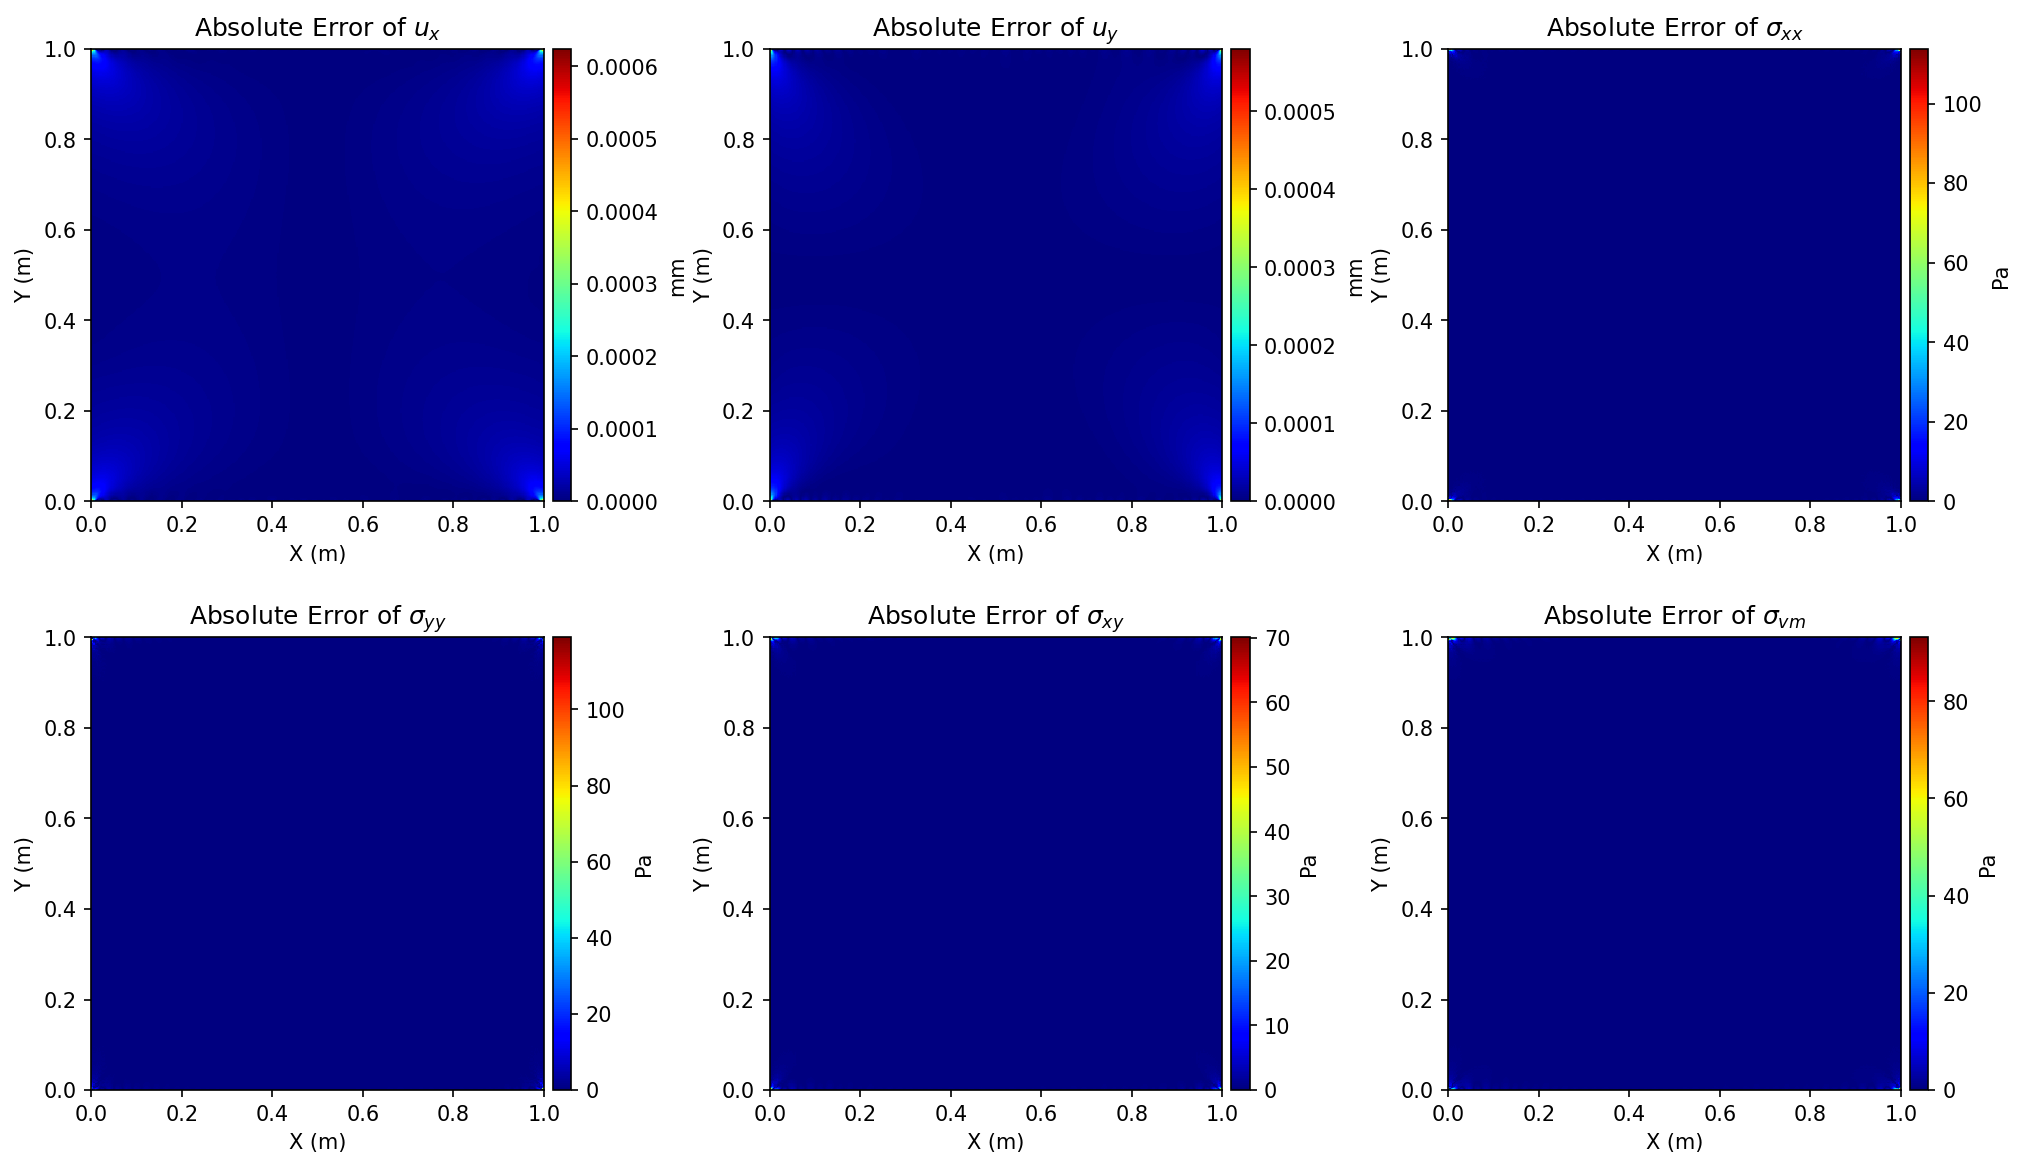

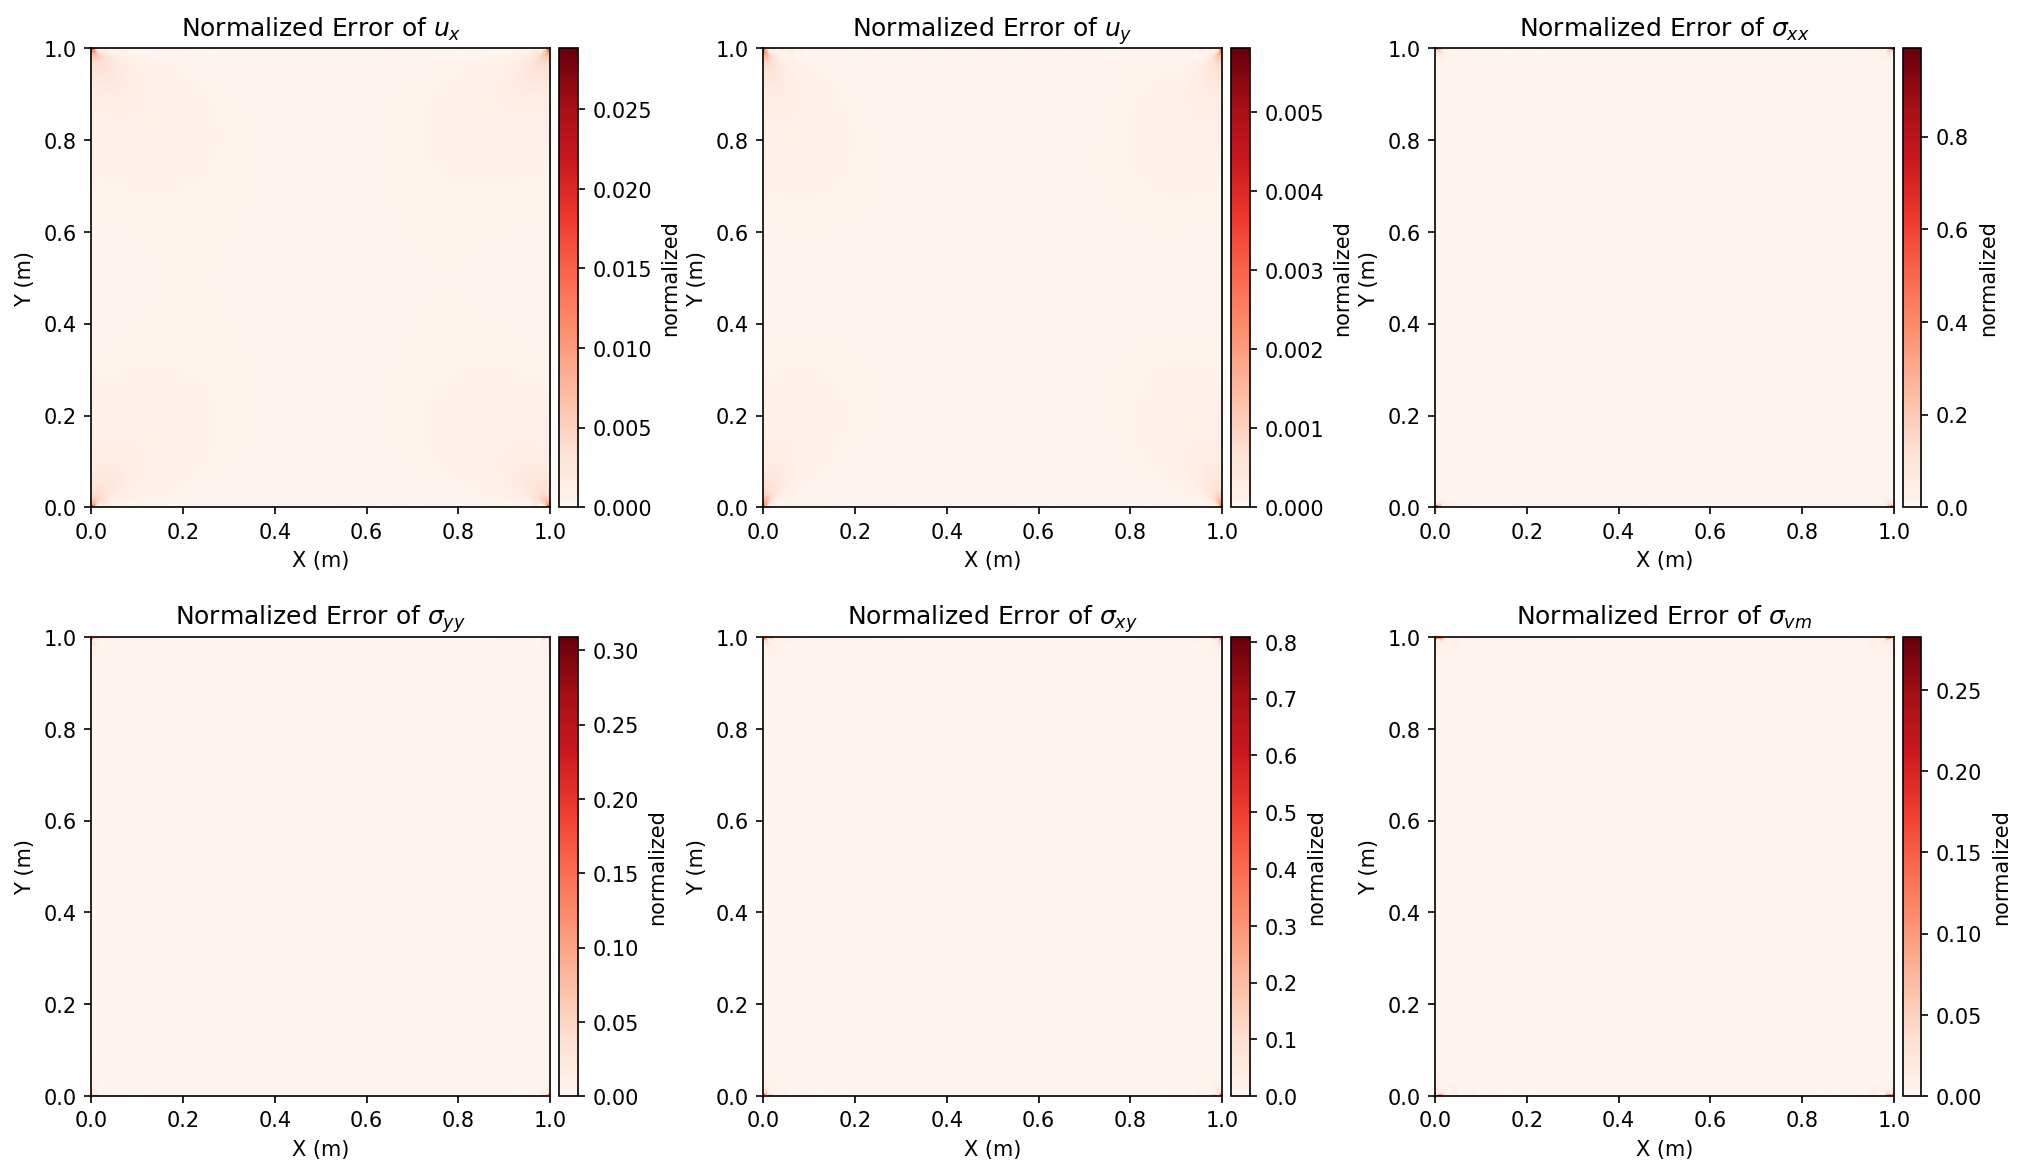

In [4]:
# ==========================================
# FSNet vs COMSOL: six-field relative L2 and normalized error clouds
# ==========================================
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

print("计算 FSNet 相对于 COMSOL 参考解的六物理量 L2 误差和归一化误差云图...")

COMSOL_REF_PATH = Path(r"C:\Users\magic\Desktop\KM-MFSNet\方板受压\方板受压comsol.txt")
FSNET_ERROR_OUT_DIR = Path(r"C:\Users\magic\Desktop\KM-MFSNet\方板受压\物理量误差云图\fsnet_comsol_error_clouds")
FSNET_ERROR_OUT_DIR.mkdir(parents=True, exist_ok=True)


def load_comsol_reference_table(txt_path=COMSOL_REF_PATH):
    """读取 COMSOL 电子表格 txt: x, y, ux, uy, sxx, syy, sxy, von_mises。"""
    txt_path = Path(txt_path)
    if not txt_path.exists():
        raise FileNotFoundError(f"找不到 COMSOL 参考解文件: {txt_path}")

    data = np.loadtxt(txt_path, comments="%")
    if data.ndim != 2 or data.shape[1] < 8:
        raise ValueError(f"COMSOL 文件至少需要 8 列，当前 shape={data.shape}")

    return {
        "points": data[:, 0:2].astype(np.float64),
        "ux": data[:, 2].astype(np.float64),
        "uy": data[:, 3].astype(np.float64),
        "sxx": data[:, 4].astype(np.float64),
        "syy": data[:, 5].astype(np.float64),
        "sxy": data[:, 6].astype(np.float64),
        "von_mises": data[:, 7].astype(np.float64),
    }


def regular_grid_from_points(points, values):
    """把 COMSOL 规则栅格电子表格数据还原成云图矩阵。"""
    x = np.asarray(points[:, 0], dtype=float)
    y = np.asarray(points[:, 1], dtype=float)
    values = np.asarray(values, dtype=float)

    xr = np.round(x, 12)
    yr = np.round(y, 12)
    xs = np.unique(xr)
    ys = np.unique(yr)

    grid = np.full((len(ys), len(xs)), np.nan, dtype=float)
    ix = np.searchsorted(xs, xr)
    iy = np.searchsorted(ys, yr)
    grid[iy, ix] = values

    if np.isnan(grid).any():
        raise ValueError("COMSOL 数据不是完整规则栅格，请在 COMSOL 中导出规则栅格电子表格。")
    return xs, ys, grid


def predict_fsnet_fields_on_points(model, pts, batch_size=10000):
    """在 COMSOL 坐标点上预测 FSNet 的六个物理量。"""
    fields = predict_fsnet_physical_fields(model, pts, batch_size=batch_size)
    return {
        "ux": fields["ux_real"],
        "uy": fields["uy_real"],
        "sxx": fields["sig_xx_real"],
        "syy": fields["sig_yy_real"],
        "sxy": fields["sig_xy_real"],
        "von_mises": fields["von_mises_real"],
    }


def relative_l2_error(pred, ref):
    pred = np.asarray(pred).reshape(-1)
    ref = np.asarray(ref).reshape(-1)
    return float(np.linalg.norm(pred - ref, 2) / max(np.linalg.norm(ref, 2), 1e-15))


def normalized_abs_error(pred, ref):
    pred = np.asarray(pred).reshape(-1)
    ref = np.asarray(ref).reshape(-1)
    return np.abs(pred - ref) / max(np.max(np.abs(ref)), 1e-15)


FIELD_ORDER = ["ux", "uy", "sxx", "syy", "sxy", "von_mises"]
FIELD_TITLES = {
    "ux": r"$u_x$",
    "uy": r"$u_y$",
    "sxx": r"$\sigma_{xx}$",
    "syy": r"$\sigma_{yy}$",
    "sxy": r"$\sigma_{xy}$",
    "von_mises": r"$\sigma_{vm}$",
}
ABS_UNITS = {
    "ux": "mm",
    "uy": "mm",
    "sxx": "Pa",
    "syy": "Pa",
    "sxy": "Pa",
    "von_mises": "Pa",
}
ABS_SCALE = {
    "ux": 1e3,
    "uy": 1e3,
    "sxx": 1.0,
    "syy": 1.0,
    "sxy": 1.0,
    "von_mises": 1.0,
}


def add_equal_height_colorbar(fig, ax, im, label):
    from mpl_toolkits.axes_grid1 import make_axes_locatable

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.06)
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label(label)
    return cbar


def plot_six_error_clouds(points, values_by_field, title_prefix, out_path, cmap, cbar_label_by_field):
    """绘制六物理量误差云图，colorbar 与云图等高。"""
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.0), dpi=150)
    for ax, key in zip(axes.ravel(), FIELD_ORDER):
        xs, ys, grid = regular_grid_from_points(points, values_by_field[key])
        im = ax.pcolormesh(xs, ys, grid, shading="auto", cmap=cmap, vmin=0.0)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("X (m)")
        ax.set_ylabel("Y (m)")
        ax.set_title(f"{title_prefix} of {FIELD_TITLES[key]}")
        add_equal_height_colorbar(fig, ax, im, cbar_label_by_field[key])

    fig.tight_layout()
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print(f"云图已保存: {out_path}")
    return fig


if "fsnet_model" not in globals():
    raise RuntimeError("请先运行 FSNet 训练单元，确保 fsnet_model 已存在。")

comsol_ref = load_comsol_reference_table()
fsnet_pred = predict_fsnet_fields_on_points(fsnet_model, comsol_ref["points"], batch_size=FSNET_PRED_BATCH_SIZE if "FSNET_PRED_BATCH_SIZE" in globals() else 10000)

metrics_rows = []
abs_error_fields = {}
normalized_error_fields = {}

for key in FIELD_ORDER:
    pred = np.asarray(fsnet_pred[key]).reshape(-1)
    ref = np.asarray(comsol_ref[key]).reshape(-1)
    abs_err = np.abs(pred - ref)
    norm_err = normalized_abs_error(pred, ref)

    abs_error_fields[key] = abs_err * ABS_SCALE[key]
    normalized_error_fields[key] = norm_err
    metrics_rows.append({
        "field": key,
        "relative_L2": relative_l2_error(pred, ref),
        "max_abs_error": float(np.max(abs_err)),
        "max_normalized_error": float(np.max(norm_err)),
    })

print("\n=== FSNet vs COMSOL 六物理量相对 L2 误差和归一化误差 ===")
print(f"{'field':>12s} {'relative_L2':>16s} {'max_abs_error':>16s} {'max_norm_error':>16s}")
for row in metrics_rows:
    print(
        f"{row['field']:>12s} "
        f"{row['relative_L2']:16.4e} "
        f"{row['max_abs_error']:16.4e} "
        f"{row['max_normalized_error']:16.4e}"
    )

metrics_path = FSNET_ERROR_OUT_DIR / "fsnet_comsol_six_field_errors.csv"
with open(metrics_path, "w", encoding="utf-8") as f:
    f.write("field,relative_L2,max_abs_error,max_normalized_error\n")
    for row in metrics_rows:
        f.write(f"{row['field']},{row['relative_L2']:.12e},{row['max_abs_error']:.12e},{row['max_normalized_error']:.12e}\n")
print(f"误差表已保存: {metrics_path}")

abs_cbar_labels = {key: ABS_UNITS[key] for key in FIELD_ORDER}
norm_cbar_labels = {key: "normalized" for key in FIELD_ORDER}

fig_fsnet_abs_error = plot_six_error_clouds(
    comsol_ref["points"],
    abs_error_fields,
    title_prefix="Absolute Error",
    out_path=FSNET_ERROR_OUT_DIR / "fsnet_comsol_absolute_error_6_clouds.png",
    cmap="jet",
    cbar_label_by_field=abs_cbar_labels,
)

fig_fsnet_normalized_error = plot_six_error_clouds(
    comsol_ref["points"],
    normalized_error_fields,
    title_prefix="Normalized Error",
    out_path=FSNET_ERROR_OUT_DIR / "fsnet_comsol_normalized_error_6_clouds.png",
    cmap="Reds",
    cbar_label_by_field=norm_cbar_labels,
)

fsnet_comsol_error_metrics = metrics_rows
fsnet_comsol_abs_error_fields = abs_error_fields
fsnet_comsol_normalized_error_fields = normalized_error_fields
